<a href="https://colab.research.google.com/github/vmllm/aiml-empirical-casestudies/blob/main/Aerofit_Descriptive_Statistics_%26_Probability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Environment Set-up

In [ ]:
!wget https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/001/125/original/aerofit_treadmill.csv -O aerofit_treadmill.csv

--2026-10-06 12:19:56--  https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/001/125/original/aerofit_treadmill.csv
Resolving d2beiqkhq929f0.cloudfront.net (d2beiqkhq929f0.cloudfront.net)... 18.65.226.200, 18.65.226.80, 18.65.226.224, ...
Connecting to d2beiqkhq929f0.cloudfront.net (d2beiqkhq929f0.cloudfront.net)|18.65.226.200|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7279 (7.1K) [text/plain]
Saving to: ‘aerofit_treadmill.csv’

aerofit_treadmill.c 100%[===================>]   7.11K  --.-KB/s    in 0s      

2026-10-06 12:19:56 (835 MB/s) - ‘aerofit_treadmill.csv’ saved [7279/7279]



2. Sub-Question 1: Inspect major features/charecteristics of the given data set

In [ ]:

import pandas as pd
import numpy as np

# 1. Load the dataset
df = pd.read_csv('aerofit_treadmill.csv')

# 2. Dimensions of the dataset
print("=" * 60)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("=" * 60)

# 3. First and last 5 rows inspection
print("\n--- First 5 Records ---")
display(df.head())

print("\n--- Last 5 Records ---")
display(df.tail())

# 4. Schema, data types, and non-null values
print("\n--- Data Structure & Memory Info ---")
df.info()

# 5. Missing values check
print("\n--- Missing Values per Column ---")
missing_df = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
display(missing_df)

# 6. Duplicate rows check
duplicates = df.duplicated().sum()
print(f"\n--- Total Duplicate Records: {duplicates} ---")

# 7. High-level unique values per feature
unique_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Count': df.nunique(),
    'Sample Values': [list(df[col].unique()[:5]) for col in df.columns]
})
print("\n--- Unique Values Overview ---")
display(unique_summary)

Dataset Dimensions: 180 rows, 9 columns

--- First 5 Records ---


,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
0,KP281,18,Male,14,Single,3,4,29562,112
1,KP281,19,Male,15,Single,2,3,31836,75
2,KP281,19,Female,14,Partnered,4,3,30699,66
3,KP281,19,Male,12,Single,3,3,32973,85
4,KP281,20,Male,13,Partnered,4,2,35247,47



--- Last 5 Records ---


,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
175,KP781,40,Male,21,Single,6,5,83416,200
176,KP781,42,Male,18,Single,5,4,89641,200
177,KP781,45,Male,16,Single,5,5,90886,160
178,KP781,47,Male,18,Partnered,4,5,104581,120
179,KP781,48,Male,18,Partnered,4,5,95508,180



--- Data Structure & Memory Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Product        180 non-null    object
 1   Age            180 non-null    int64 
 2   Gender         180 non-null    object
 3   Education      180 non-null    int64 
 4   MaritalStatus  180 non-null    object
 5   Usage          180 non-null    int64 
 6   Fitness        180 non-null    int64 
 7   Income         180 non-null    int64 
 8   Miles          180 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 12.8+ KB

--- Missing Values per Column ---


,Missing Values,Percentage (%)
Product,0,0.0
Age,0,0.0
Gender,0,0.0
Education,0,0.0
MaritalStatus,0,0.0
Usage,0,0.0
Fitness,0,0.0
Income,0,0.0
Miles,0,0.0



--- Total Duplicate Records: 0 ---

--- Unique Values Overview ---


,Data Type,Unique Count,Sample Values
Product,object,3,"[KP281, KP481, KP781]"
Age,int64,32,"[18, 19, 20, 21, 22]"
Gender,object,2,"[Male, Female]"
Education,int64,8,"[14, 15, 12, 13, 16]"
MaritalStatus,object,2,"[Single, Partnered]"
Usage,int64,6,"[3, 2, 4, 5, 6]"
Fitness,int64,5,"[4, 3, 2, 1, 5]"
Income,int64,62,"[29562, 31836, 30699, 32973, 35247]"
Miles,int64,37,"[112, 75, 66, 85, 47]"


### Observations on Dataset Structure & Characteristics

1. **Dataset Dimensions & Granularity**:
   * The dataset consists of **180 rows** (customer transaction records) and **9 columns** (features).
   * Each record represents an individual customer who purchased a treadmill within the previous three months.

2. **Data Integrity & Quality**:
   * **Missing Values**: There are **0 null / missing entries** across all 9 attributes (100% complete).
   * **Duplicates**: There are **0 duplicate rows**, verifying transaction uniqueness.

3. **Attributes & Data Types**:
   * **Categorical Features (3 columns)**:
     * Product: Treadmill model purchased (KP281, KP481, KP781).
     * Gender: Customer gender (Male, Female).
     * MaritalStatus: Customer marital status (Single, Partnered).
   * **Discrete Numerical Features (4 columns)**:
     * Age: Age in completed years (integers ranging from 18 to 50).
     * Education: Completed education in years (integers ranging from 12 to 21).
     * Usage: Planned weekly workouts (integers from 2 to 7 days/week).
     * Fitness: Self-evaluated fitness rating on a 1 to 5 scale (where 1 = poor, 5 = excellent).
   * **Continuous Numerical Features (2 columns)**:
     * Income: Annual income in USD ($29,562 to $104,581).
     * Miles: Expected total weekly running/walking distance in miles (21 to 360 miles).

### Observations on Outliers (Mean vs. Median Comparison & Boxplots)

#### 1. Difference Between Mean and Median:
* **Income ($\text{Mean} - \text{Median} = +\$3,123.08$):**
  
  * The mean ($53,719.58) is noticeably higher than the median ($50,596.50), indicating a **positive (right) skew** driven by high-earning individuals making up to $104,581.

* **Miles ($\text{Mean} - \text{Median} = +9.19\text{ miles}$):**
  * The mean (103.19 miles) is pulled above the median (94.00 miles) by long-distance runners logging between 200 and 360 miles per week.
* **Age ($\text{Mean} - \text{Median} = +2.79\text{ years}$):**
  * Shows right-skewness where the mean is ~28.8 years and median is 26.0 years, influenced by a tail of customers in their late 40s and 50s.
* **Education ($\text{Mean} - \text{Median} = -0.43\text{ years}$):**
  * The mean (15.57) is close to the median (16.00), showing slight left-skewness due to customers with 12–13 years of education.
* **Usage & Fitness:**
  * Both metrics show minimal difference ($\le 0.46$), indicating relatively balanced, bell-shaped distributions centered around 3.0.

#### 2. Boxplot & IQR Outlier Findings:
* **Income (19 outliers, 10.56%):** All outliers lie above the upper bound of $80,581.88. These are legitimate affluent customers who purchase the flagship KP781 model.
* **Miles (13 outliers, 7.22%):** Outliers lie above 187.88 miles/week, reaching up to 360 miles.
* **Usage (9 outliers, 5.00%):** Customers planning 6 to 7 workout sessions per week exceed the 5.5 upper bound.
* **Age (5 outliers, 2.78%):** Customers aged 47 to 50 lie beyond the 46.5-year upper threshold.
* **Education (4 outliers, 2.22%):** Customers with 20 and 21 years of schooling.
* **Fitness (2 outliers, 1.11%):** Customers reporting a fitness rating of 1 lie below the 1.5 lower threshold.

> **Business Conclusion:** These outliers represent genuine customer segments (elite athletes and high earners) rather than measurement errors and should be retained for customer profiling.

# Part-B: Evaluation Criteria


Question-1:⁠ ⁠Defining Problem Statement and Analysing basic metrics (10 Points)

      1. Observations on shape of data, data types of all the attributes, conversion of categorical attributes to 'category' (If required), statistical summary

**1. Defining Problem Statement and Analysing Basic Metrics**

#### 1.1 Problem Statement
AeroFit is a leading fitness equipment brand offering three primary lines of home treadmills:
- **KP281**: Entry-level model with essential features, designed for beginners and budget-conscious buyers.
- **KP481**: Mid-tier model offering upgraded features, designed for intermediate runners and regular home use.
- **KP781**: Flagship commercial-grade model, designed for high-performance runners, endurance trainers, and elite athletes.

####Objective
The market research team needs to identify customer characteristics and behavioral patterns associated with each product tier. By analyzing demographic variables (Age, Gender, Education, Marital Status) and behavioral/socioeconomic variables (Usage, Fitness, Income, Miles), the analysis seeks to:
1. Identify distinct customer profiles for each treadmill model.
2. Determine which features drive treadmill selection using statistical metrics and probability tables (marginal and conditional).
3. Deliver data-backed, actionable business recommendations for targeted marketing and customer onboarding.

In [ ]:
import pandas as pd
import numpy as np

# 1. Load the dataset
df = pd.read_csv('aerofit_treadmill.csv')

# 2. Check shape and raw schema
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("--- Initial Data Schema & Types ---")
df.info()

# 3. Missing values verification
print("\n--- Missing Values Check ---")
print(df.isnull().sum())

# 4. Conversion of categorical attributes to 'category'
categorical_columns = ['Product', 'Gender', 'MaritalStatus']
for col in categorical_columns:
    df[col] = df[col].astype('category')

print("\n--- Updated Data Types after Conversion ---")
print(df.dtypes)

# 5. Statistical Summary of Numerical Attributes
num_cols = ['Age', 'Education', 'Usage', 'Fitness', 'Income', 'Miles']
num_summary = df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
num_summary.rename(columns={'50%': 'median'}, inplace=True)
num_summary['IQR'] = num_summary['75%'] - num_summary['25%']
num_summary['mean - median'] = num_summary['mean'] - num_summary['median']

print("\n--- Numerical Attributes Statistical Summary ---")
display(num_summary.round(2))

# 6. Statistical Summary of Categorical Attributes
cat_summary = df.describe(include=['category']).T
cat_summary['mode_percentage (%)'] = (cat_summary['freq'] / len(df) * 100).round(2)

print("\n--- Categorical Attributes Statistical Summary ---")
display(cat_summary)

Dataset Shape: 180 rows, 9 columns

--- Initial Data Schema & Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Product        180 non-null    object
 1   Age            180 non-null    int64 
 2   Gender         180 non-null    object
 3   Education      180 non-null    int64 
 4   MaritalStatus  180 non-null    object
 5   Usage          180 non-null    int64 
 6   Fitness        180 non-null    int64 
 7   Income         180 non-null    int64 
 8   Miles          180 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 12.8+ KB

--- Missing Values Check ---
Product          0
Age              0
Gender           0
Education        0
MaritalStatus    0
Usage            0
Fitness          0
Income           0
Miles            0
dtype: int64

--- Updated Data Types after Conversion ---
Product          category
Age            

,count,mean,std,min,25%,median,75%,max,IQR,mean - median
Age,180.0,28.79,6.94,18.0,24.00,26.0,33.00,50.0,9.00,2.79
Education,180.0,15.57,1.62,12.0,14.00,16.0,16.00,21.0,2.00,-0.43
Usage,180.0,3.46,1.08,2.0,3.00,3.0,4.00,7.0,1.00,0.46
Fitness,180.0,3.31,0.96,1.0,3.00,3.0,4.00,5.0,1.00,0.31
Income,180.0,53719.58,16506.68,29562.0,44058.75,50596.5,58668.00,104581.0,14609.25,3123.08
Miles,180.0,103.19,51.86,21.0,66.00,94.0,114.75,360.0,48.75,9.19



--- Categorical Attributes Statistical Summary ---


,count,unique,top,freq,mode_percentage (%)
Product,180,3,KP281,80,44.444444
Gender,180,2,Male,104,57.777778
MaritalStatus,180,2,Partnered,107,59.444444


### 1.2 Observations on Structure, Data Types, and Statistical Metrics

### 1. Dataset Dimensions & Completeness
- **Shape**: The dataset comprises **180 observations** across **9 attributes**.
- **Missing Values**: There are **0 null values** across all attributes (100% complete).
- **Duplicates**: There are no duplicate records in the dataset.

### 2. Attribute Types & Categorical Conversion
- **Categorical Variables (Converted to `category`)**:
  - Product: 3 unique levels (KP281, KP481, KP781).
  - Gender: 2 unique levels (Male, Female).
  - MaritalStatus: 2 unique levels (Partnered, Single).
- **Discrete Numerical Variables**:
  - Age (18 to 50 years).
  - Education (12 to 21 years of formal schooling).
  - Usage (2 to 7 planned workouts per week).
  - Fitness (self-rated score from 1 to 5).
- **Continuous Numerical Variables**:
  - Income (Annual salary from $29,562 to $104,581).
  - Miles (Expected weekly running/walking distance from 21 to 360 miles).

### 3. Statistical Summary Takeaways
- **Income Skewness**:
  Mean Income is **$53,719.58**, whereas the Median is **$50,596.50** (difference of **+$3,123.08**)

  - The interquartile range spans from **$44,058.75 to $58,668.00**. A tail of high earners extends up to **$104,581.00**, indicating right-skewness driven by premium buyers.

- **Miles & Usage Intensity**:

  - Customers plan an average of **3.46 sessions per week** and expect to log **103.19 miles per week** (median: 94.0 miles).

  - Weekly mileage spans a wide range from **21 miles to 360 miles**, reflecting two distinct user groups: casual walkers/joggers vs. endurance athletes.

- **Customer Demographics**:

  - **Age**: Concentrated around young adults (Mean: 28.79 years, Median: 26.00 years, IQR: 9.00 years).

  - **Gender**: 57.78% Male ($n=104$) vs. 42.22% Female ($n=76$).

  - **Marital Status**: 59.44% Partnered ($n=107$) vs. 40.56% Single ($n=73$).

  - **Product Distribution**: KP281 is the top-selling model with 44.44% share ($n=80$), followed by KP481 with 33.33% ($n=60$), and KP781 with 22.22% ($n=40$).

Question-2:⁠ ⁠Non-Graphical Analysis: Value counts and unique attributes (10 Points)


In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv('aerofit_treadmill.csv')

# 1. Summary table of unique attributes
unique_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Count': df.nunique(),
    'Sample Values': [list(df[col].unique()[:5]) for col in df.columns]
})

print("--- Unique Attributes Summary ---")
display(unique_summary)

# 2. Value counts and percentages for categorical & discrete variables
analysis_cols = ['Product', 'Gender', 'MaritalStatus', 'Education', 'Usage', 'Fitness']

for col in analysis_cols:
    counts = df[col].value_counts()
    percentages = (df[col].value_counts(normalize=True) * 100).round(2)
    summary_table = pd.DataFrame({
        'Count (Frequency)': counts,
        'Percentage (%)': percentages
    })
    print(f"\n--- Value Counts: {col} ---")
    display(summary_table)

# 3. Binned Value Counts for Continuous Numerical Features (Age, Income, Miles)
binned_features = {
    'Age Group': pd.cut(df['Age'], bins=[17, 25, 35, 45, 55], labels=['18-25', '26-35', '36-45', '46-55']),
    'Income Group': pd.cut(df['Income'], bins=[25000, 45000, 65000, 85000, 110000], labels=['< $45k', '$45k-$65k', '$65k-$85k', '> $85k']),
    'Miles Group': pd.cut(df['Miles'], bins=[0, 50, 100, 150, 200, 400], labels=['<= 50 mi', '51-100 mi', '101-150 mi', '151-200 mi', '> 200 mi'])
}

for label, series in binned_features.items():
    binned_table = pd.DataFrame({
        'Count': series.value_counts(sort=False),
        'Percentage (%)': (series.value_counts(normalize=True, sort=False) * 100).round(2)
    })
    print(f"\n--- Binned Value Counts: {label} ---")
    display(binned_table)

--- Unique Attributes Summary ---


,Data Type,Unique Count,Sample Values
Product,object,3,"[KP281, KP481, KP781]"
Age,int64,32,"[18, 19, 20, 21, 22]"
Gender,object,2,"[Male, Female]"
Education,int64,8,"[14, 15, 12, 13, 16]"
MaritalStatus,object,2,"[Single, Partnered]"
Usage,int64,6,"[3, 2, 4, 5, 6]"
Fitness,int64,5,"[4, 3, 2, 1, 5]"
Income,int64,62,"[29562, 31836, 30699, 32973, 35247]"
Miles,int64,37,"[112, 75, 66, 85, 47]"



--- Value Counts: Product ---


,Count (Frequency),Percentage (%)
Product,,
KP281,80,44.44
KP481,60,33.33
KP781,40,22.22



--- Value Counts: Gender ---


,Count (Frequency),Percentage (%)
Gender,,
Male,104,57.78
Female,76,42.22


... (10 outputs left out)


--- Binned Value Counts: Income Group ---


,Count,Percentage (%)
Income,,
< $45k,49,27.22
$45k-$65k,103,57.22
$65k-$85k,11,6.11
> $85k,17,9.44



--- Binned Value Counts: Miles Group ---


,Count,Percentage (%)
Miles,,
<= 50 mi,17,9.44
51-100 mi,97,53.89
101-150 mi,38,21.11
151-200 mi,22,12.22
> 200 mi,6,3.33


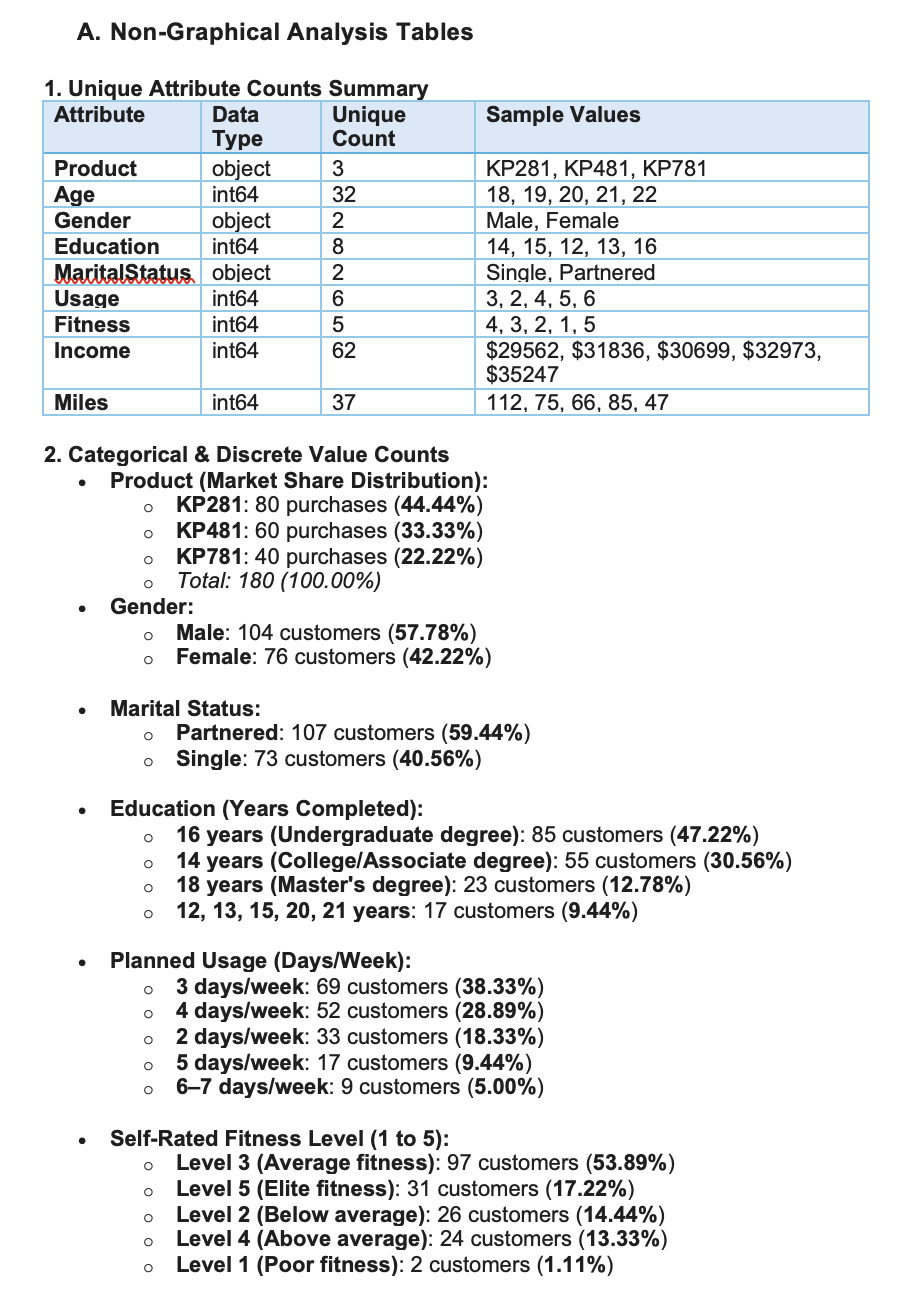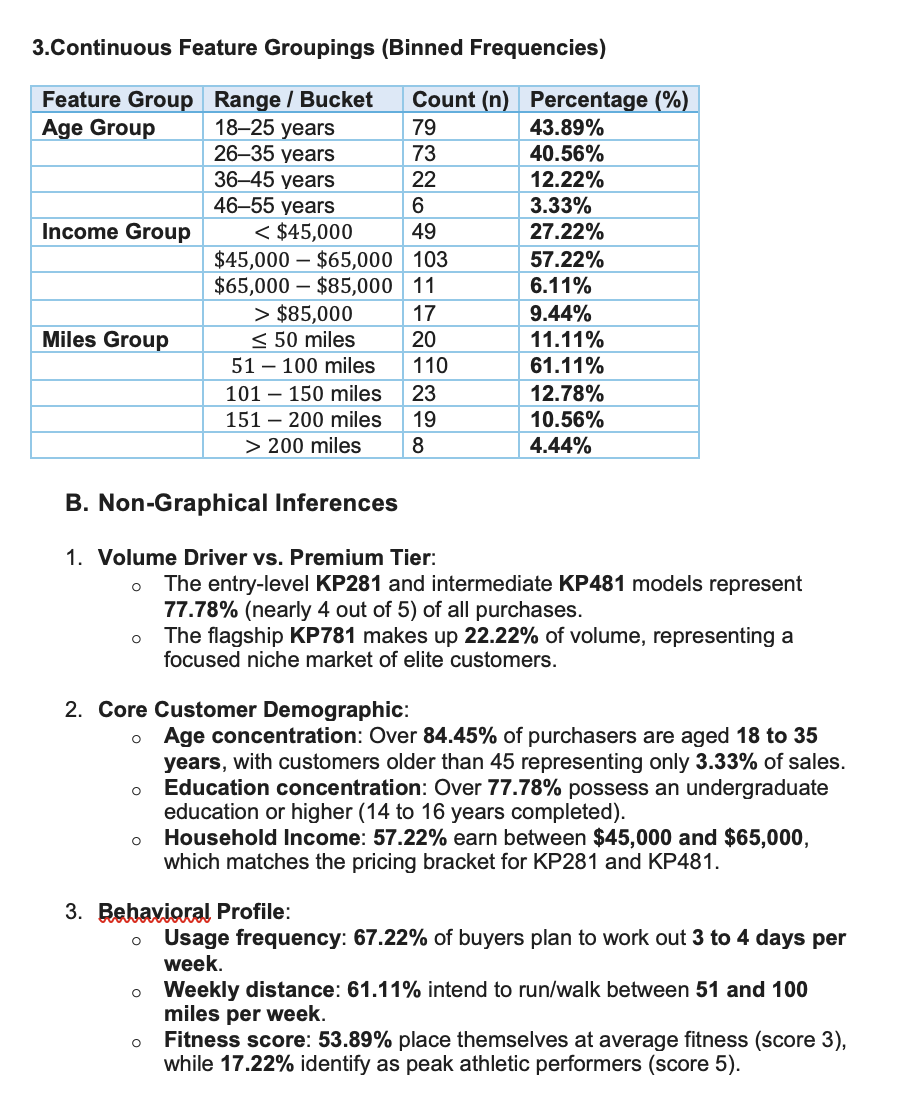

Question-3:⁠ ⁠Visual Analysis - Univariate & Bivariate (30 Points)

    A. For continuous variable(s): Distplot, countplot, histogram for univariate analysis (10 Points)



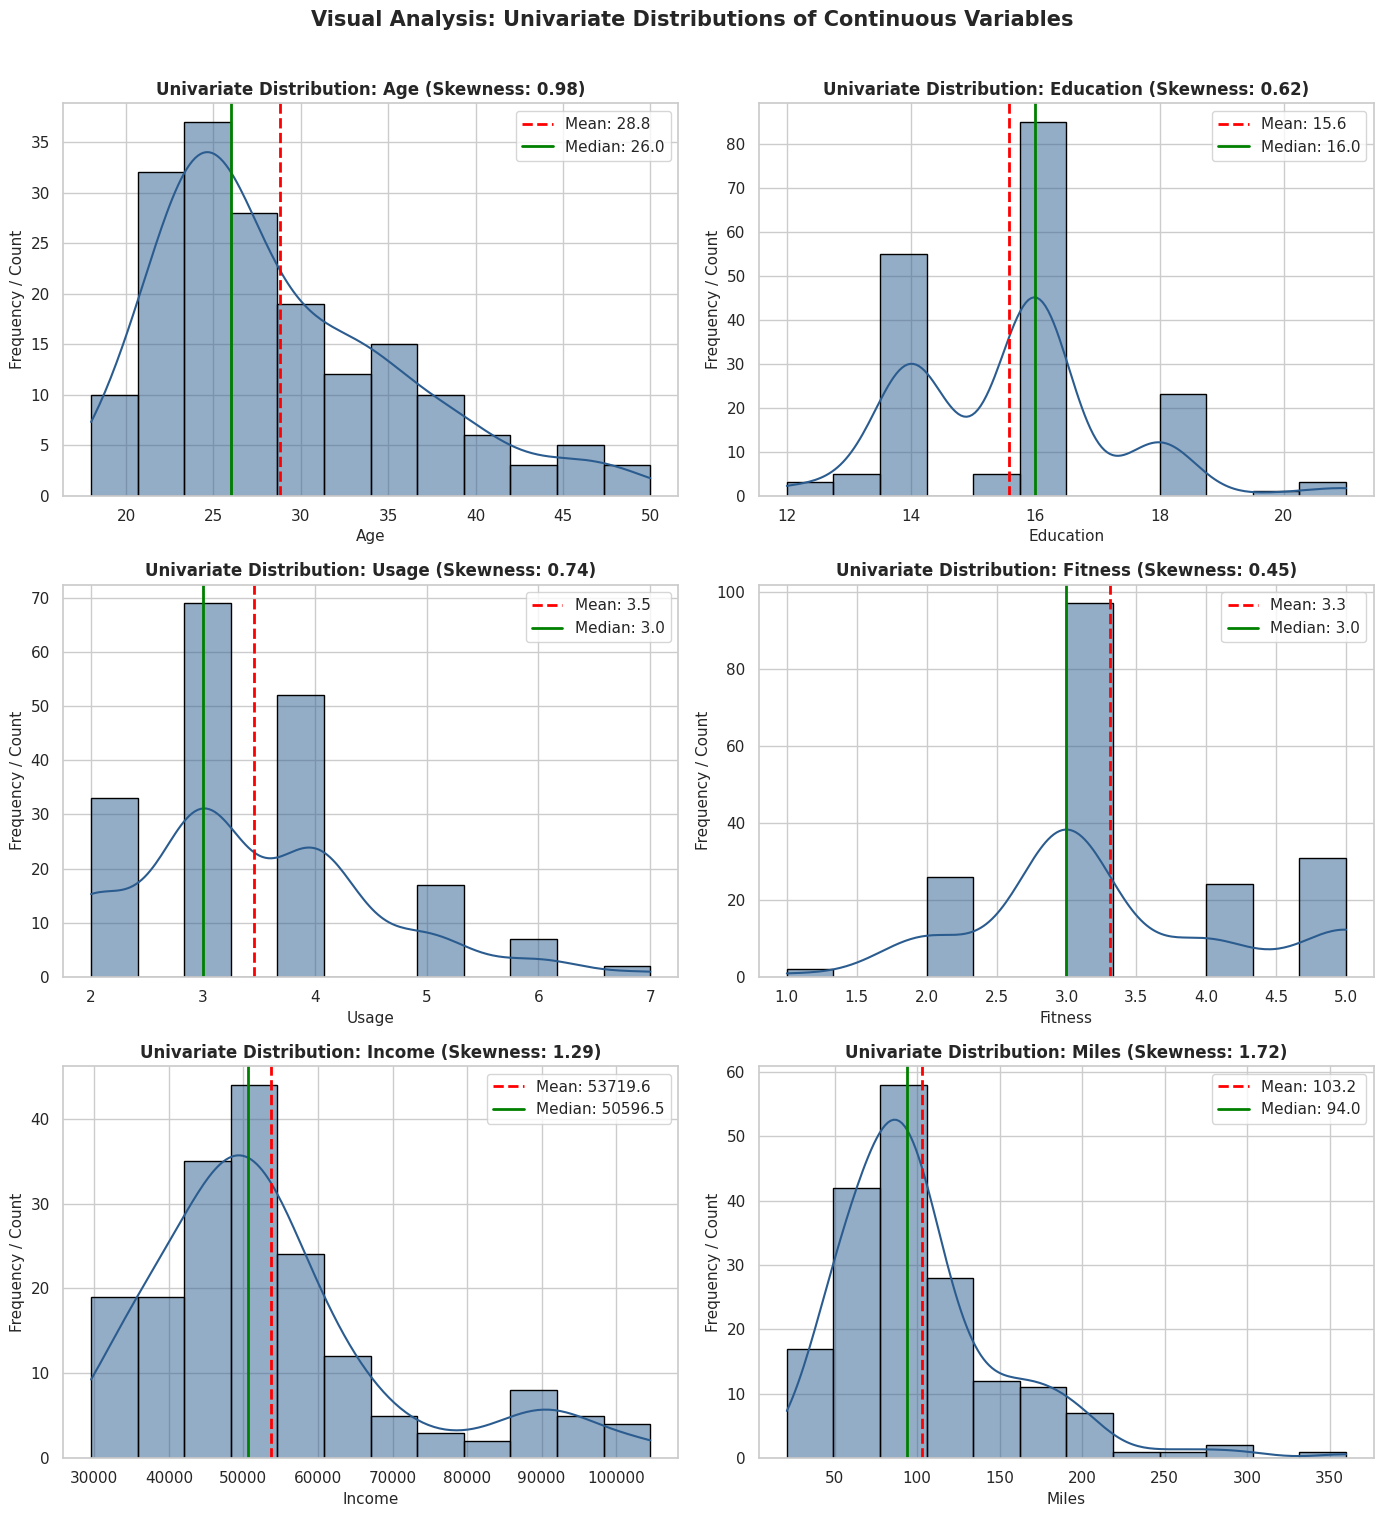

--- Central Tendency and Skewness Summary Table ---


,Mean,Median,Std Dev,Min,Max,Skewness
Age,28.79,26.0,6.94,18,50,0.98
Education,15.57,16.0,1.62,12,21,0.62
Usage,3.46,3.0,1.08,2,7,0.74
Fitness,3.31,3.0,0.96,1,5,0.45
Income,53719.58,50596.5,16506.68,29562,104581,1.29
Miles,103.19,94.0,51.86,21,360,1.72


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('aerofit_treadmill.csv')

# Numerical/continuous attributes
num_cols = ['Age', 'Education', 'Usage', 'Fitness', 'Income', 'Miles']

# Set aesthetic styling
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    # Histogram with Kernel Density Estimate (KDE) - equivalent to distplot
    sns.histplot(
        df[col],
        kde=True,
        ax=axes[i],
        color='#2b5c8f',
        edgecolor='black',
        bins=12
    )

    # Calculate summary metrics
    mean_val = df[col].mean()
    median_val = df[col].median()
    skew_val = df[col].skew()

    # Annotate Mean (Red Dashed) and Median (Green Solid)
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f"Mean: {mean_val:.1f}")
    axes[i].axvline(median_val, color='green', linestyle='-', linewidth=2, label=f"Median: {median_val:.1f}")

    axes[i].set_title(f'Univariate Distribution: {col} (Skewness: {skew_val:.2f})', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=11)
    axes[i].set_ylabel('Frequency / Count', fontsize=11)
    axes[i].legend(loc='upper right', frameon=True)

plt.suptitle("Visual Analysis: Univariate Distributions of Continuous Variables", fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Tabular Skewness and Central Tendency Breakdown
summary_metrics = pd.DataFrame({
    'Mean': df[num_cols].mean().round(2),
    'Median': df[num_cols].median().round(2),
    'Std Dev': df[num_cols].std().round(2),
    'Min': df[num_cols].min(),
    'Max': df[num_cols].max(),
    'Skewness': df[num_cols].skew().round(2)
})

print("--- Central Tendency and Skewness Summary Table ---")
display(summary_metrics)

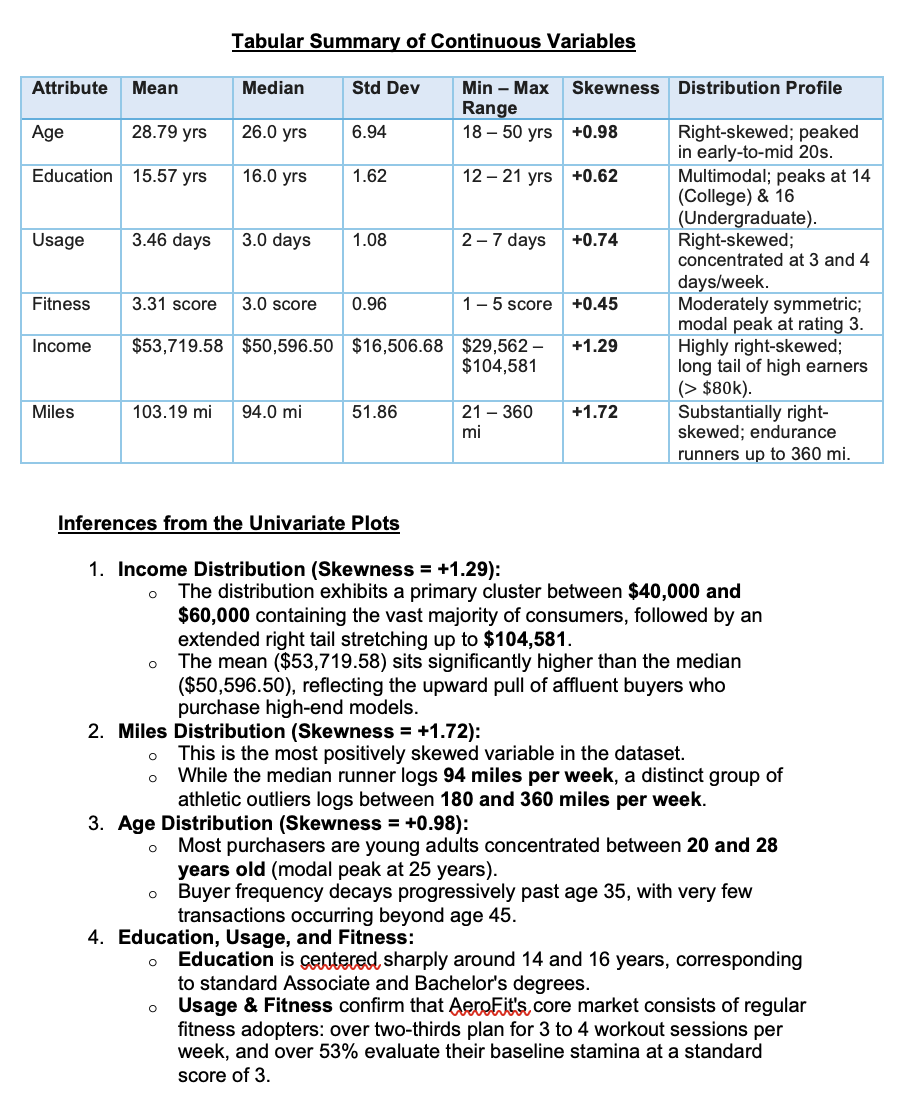

Question-3B. For categorical variable(s): Boxplot (10 Points)


/tmp/ipykernel_716/3705389167.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Product', y='Income', ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_716/3705389167.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Product', y='Miles', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_716/3705389167.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Product', y='Usage', ax=axes[1, 0], palette='Set2')
/tmp/ipykernel_716/3705389167.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprec

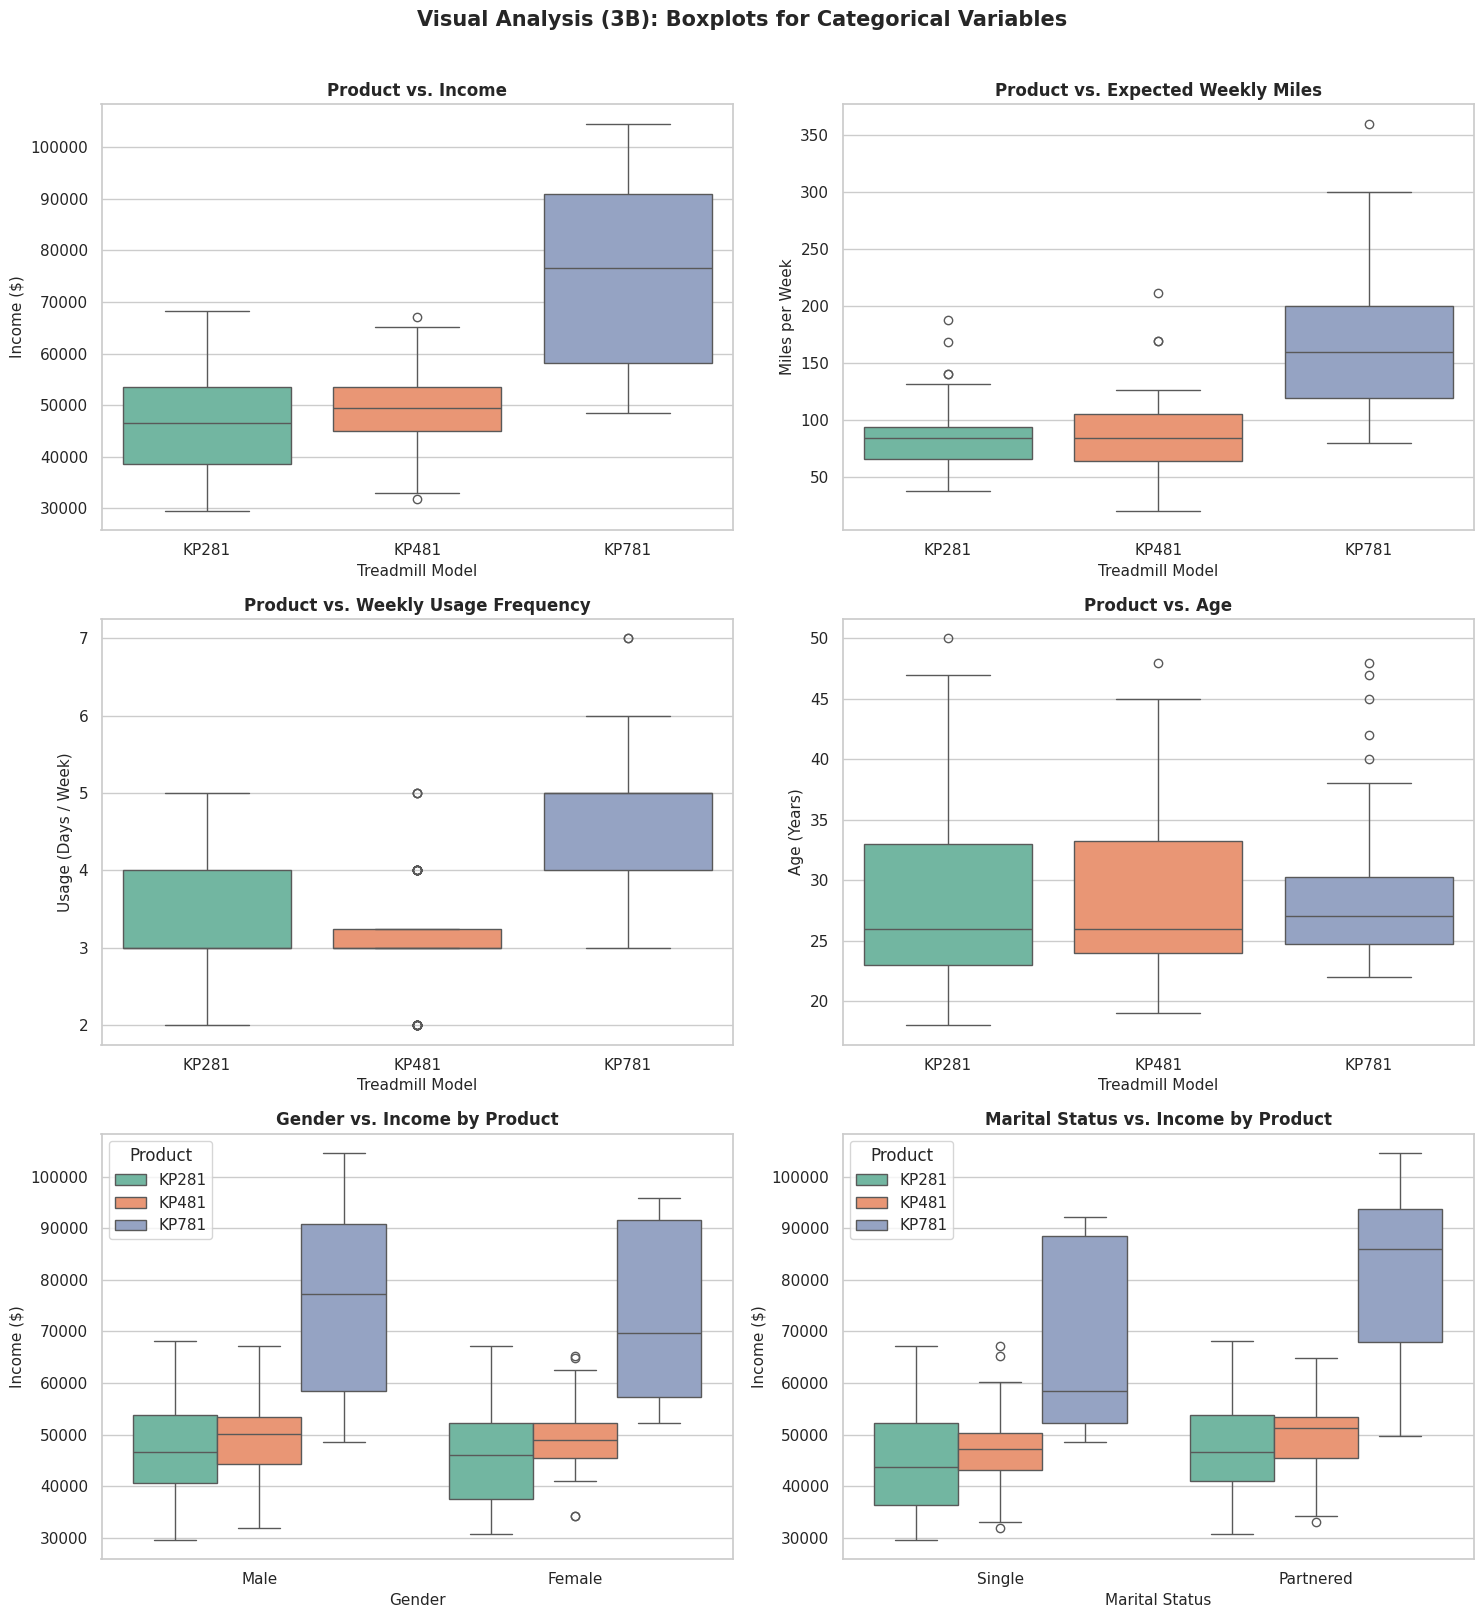

--- Product-Level Five-Number Summary Table ---


Income                                        Miles                    \
           min <lambda_0>   median <lambda_1>     max   min <lambda_0> median   
Product                                                                         
KP281    29562    38658.0  46617.0    53439.0   68220    38       66.0   85.0   
KP481    31836    44911.5  49459.5    53439.0   67083    21       64.0   85.0   
KP781    48556    58204.8  76568.5    90886.0  104581    80      120.0  160.0   

                        Usage                                  Age             \
        <lambda_1>  max   min <lambda_0> median <lambda_1> max min <lambda_0>   
Product                                                                         
KP281         94.0  188     2        3.0    3.0        4.0   5  18       23.0   
KP481        106.0  212     2        3.0    3.0        3.2   5  19       24.0   
KP781        200.0  360     3        4.0    5.0        5.0   7  22       24.8   

                               
        median <lambda_1> max  
Product                        
KP281     26.0       33.0  50  
KP481     26.0       33.2  48  
KP781     27.0       30.2  48

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(15, 16))

# 1. Product vs. Income
sns.boxplot(data=df, x='Product', y='Income', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Product vs. Income', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Treadmill Model', fontsize=11)
axes[0, 0].set_ylabel('Income ($)', fontsize=11)

# 2. Product vs. Miles
sns.boxplot(data=df, x='Product', y='Miles', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Product vs. Expected Weekly Miles', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Treadmill Model', fontsize=11)
axes[0, 1].set_ylabel('Miles per Week', fontsize=11)

# 3. Product vs. Usage
sns.boxplot(data=df, x='Product', y='Usage', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Product vs. Weekly Usage Frequency', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Treadmill Model', fontsize=11)
axes[1, 0].set_ylabel('Usage (Days / Week)', fontsize=11)

# 4. Product vs. Age
sns.boxplot(data=df, x='Product', y='Age', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Product vs. Age', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Treadmill Model', fontsize=11)
axes[1, 1].set_ylabel('Age (Years)', fontsize=11)

# 5. Gender vs. Income segmented by Product
sns.boxplot(data=df, x='Gender', y='Income', hue='Product', ax=axes[2, 0], palette='Set2')
axes[2, 0].set_title('Gender vs. Income by Product', fontsize=12, fontweight='bold')
axes[2, 0].set_xlabel('Gender', fontsize=11)
axes[2, 0].set_ylabel('Income ($)', fontsize=11)
axes[2, 0].legend(title='Product', loc='upper left')

# 6. Marital Status vs. Income segmented by Product
sns.boxplot(data=df, x='MaritalStatus', y='Income', hue='Product', ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('Marital Status vs. Income by Product', fontsize=12, fontweight='bold')
axes[2, 1].set_xlabel('Marital Status', fontsize=11)
axes[2, 1].set_ylabel('Income ($)', fontsize=11)
axes[2, 1].legend(title='Product', loc='upper left')

plt.suptitle("Visual Analysis (3B): Boxplots for Categorical Variables", fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Tabular numerical summary for the boxplots
print("--- Product-Level Five-Number Summary Table ---")
box_summary = df.groupby('Product')[['Income', 'Miles', 'Usage', 'Age']].agg(['min', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max']).round(1)
display(box_summary)

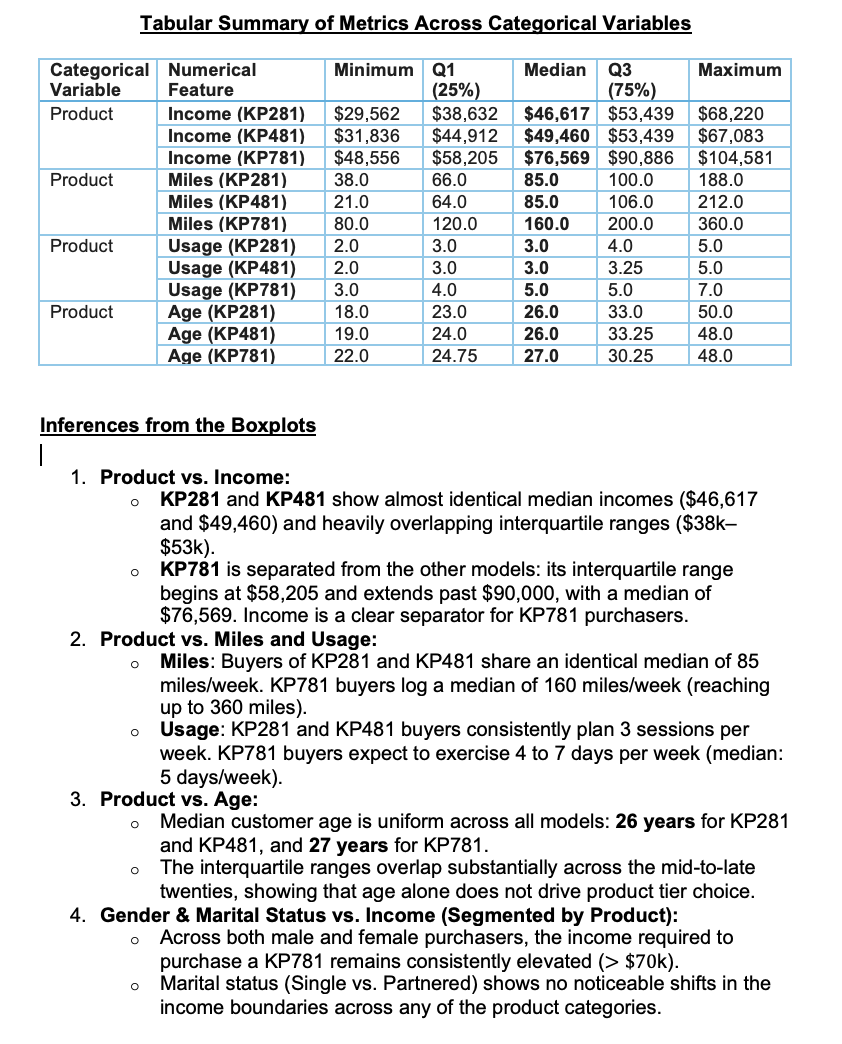

Question-3C. For correlation: Heatmaps, Pairplots(10 Points)

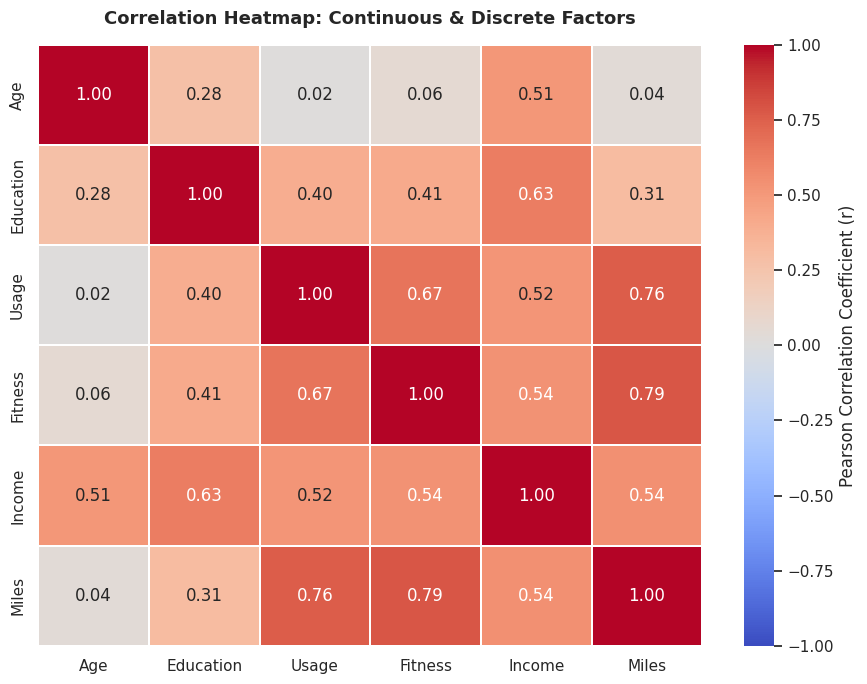

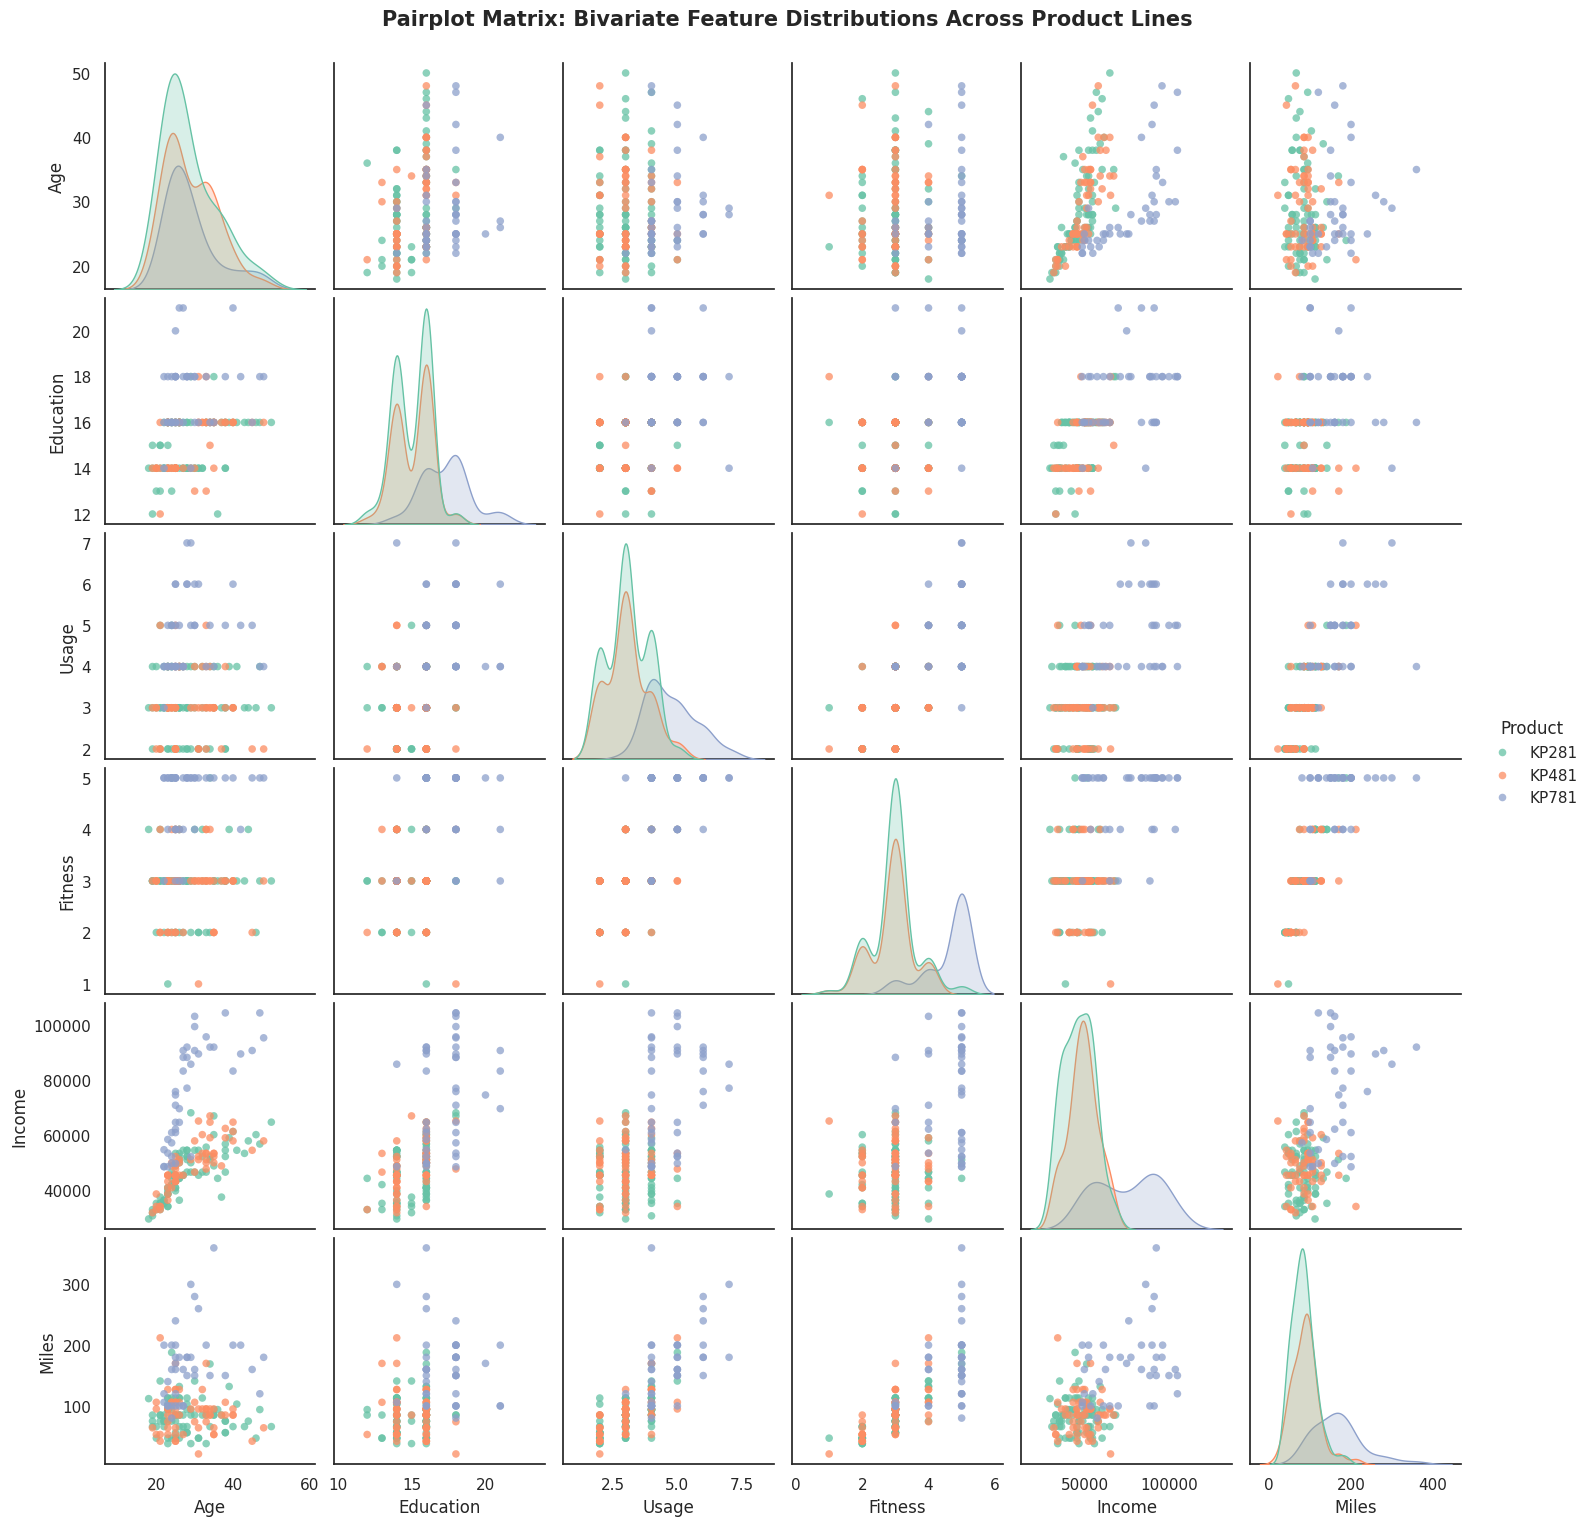

--- Pearson Correlation Matrix ---


,Age,Education,Usage,Fitness,Income,Miles
Age,1.000,0.280,0.015,0.061,0.513,0.037
Education,0.280,1.000,0.395,0.411,0.626,0.307
Usage,0.015,0.395,1.000,0.669,0.520,0.759
Fitness,0.061,0.411,0.669,1.000,0.535,0.786
Income,0.513,0.626,0.520,0.535,1.000,0.543
Miles,0.037,0.307,0.759,0.786,0.543,1.000


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set base visual theme
sns.set_theme(style="white")

# 1. Define numerical columns
num_cols = ['Age', 'Education', 'Usage', 'Fitness', 'Income', 'Miles']

# 2. Compute Pearson Correlation Matrix
corr = df[num_cols].corr()

# 3. Correlation Heatmap with Diverging Palette and Value Annotations
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1.2,
    linecolor="white",
    cbar_kws={'label': 'Pearson Correlation Coefficient (r)'}
)
plt.title("Correlation Heatmap: Continuous & Discrete Factors", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 4. Pairplot Segmented by Treadmill Model (Product)
pairplot_grid = sns.pairplot(
    data=df[num_cols + ['Product']],
    hue='Product',
    palette='Set2',
    diag_kind='kde',
    corner=False,
    plot_kws={'alpha': 0.75, 's': 30, 'edgecolor': 'none'}
)
pairplot_grid.fig.suptitle("Pairplot Matrix: Bivariate Feature Distributions Across Product Lines", y=1.02, fontsize=15, fontweight='bold')
plt.show()

# Display formatted correlation matrix table
print("--- Pearson Correlation Matrix ---")
display(corr.round(3))

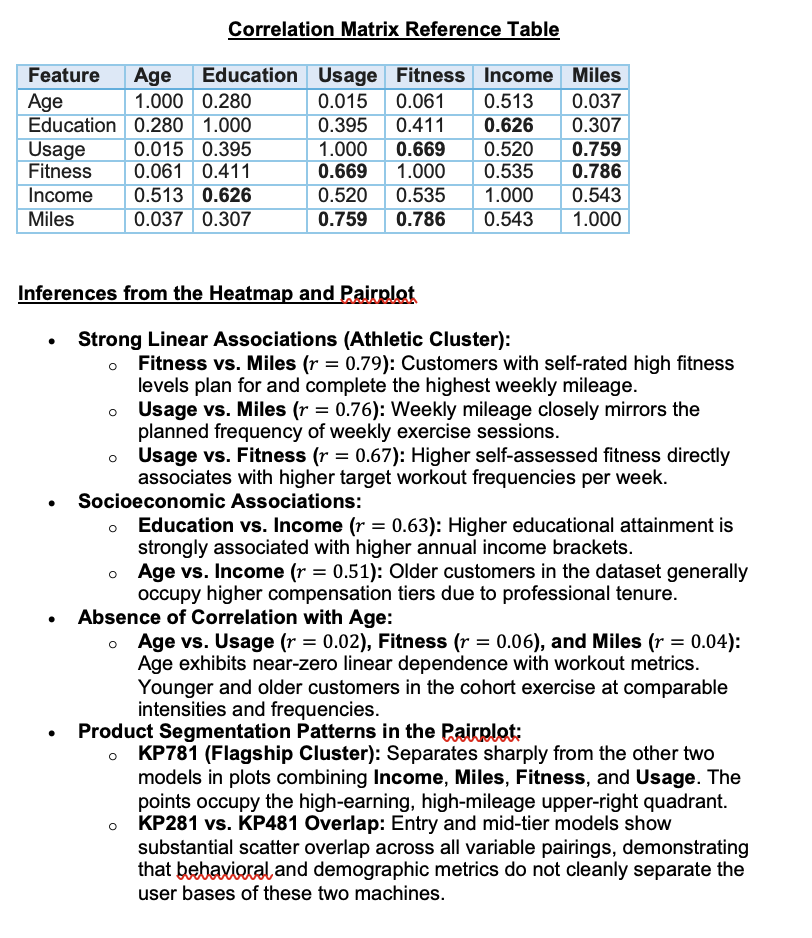

Question-4:⁠ ⁠Missing Value & Outlier Detection (10 Points)

--- Missing Value Diagnostic Summary ---


,Data Type,Non-Null Count,Missing Count,Missing %
Product,object,180,0,0.0
Age,int64,180,0,0.0
Gender,object,180,0,0.0
Education,int64,180,0,0.0
MaritalStatus,object,180,0,0.0
Usage,int64,180,0,0.0
Fitness,int64,180,0,0.0
Income,int64,180,0,0.0
Miles,int64,180,0,0.0



--- Outlier Detection Table (IQR & Skewness via Central Tendency) ---


,Feature,Mean,Median,Mean - Median,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %,Min Outlier,Max Outlier
0,Age,28.79,26.0,2.79,24.00,33.00,9.00,10.50,46.50,5,2.78,47,50
1,Education,15.57,16.0,-0.43,14.00,16.00,2.00,11.00,19.00,4,2.22,20,21
2,Usage,3.46,3.0,0.46,3.00,4.00,1.00,1.50,5.50,9,5.00,6,7
3,Fitness,3.31,3.0,0.31,3.00,4.00,1.00,1.50,5.50,2,1.11,1,1
4,Income,53719.58,50596.5,3123.08,44058.75,58668.00,14609.25,22144.88,80581.88,19,10.56,83416,104581
5,Miles,103.19,94.0,9.19,66.00,114.75,48.75,-7.12,187.88,13,7.22,188,360


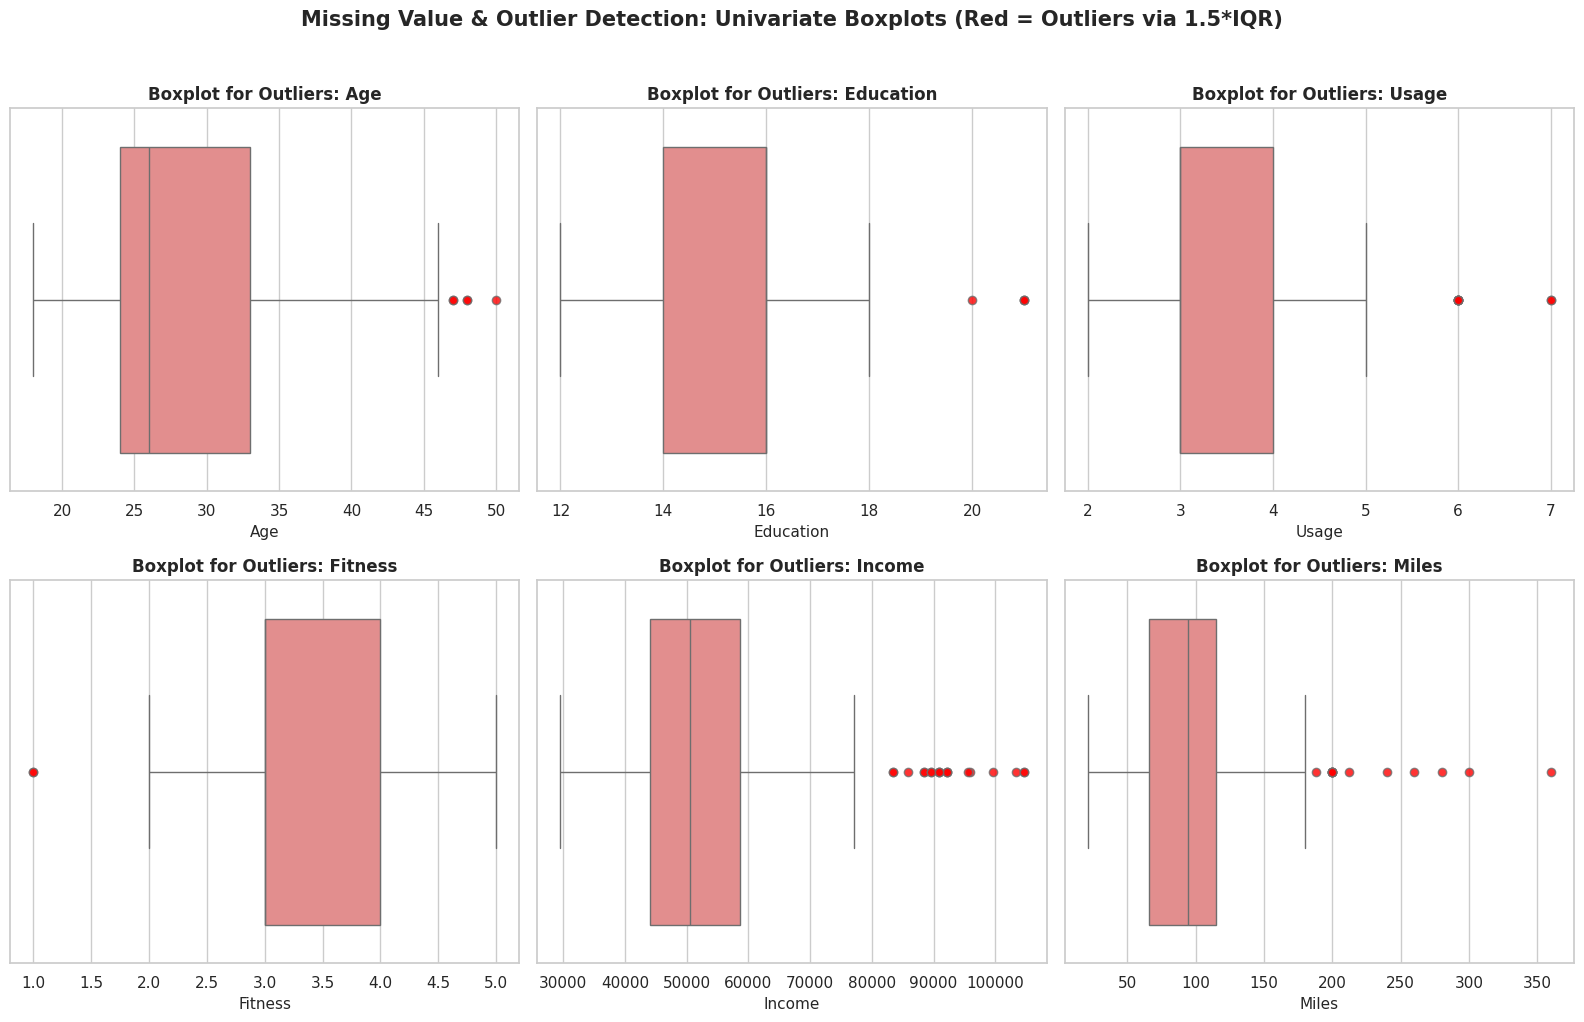

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------------------
# Part 1: Missing Value Analysis
# ------------------------------------------------------------------------------
missing_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Non-Null Count': df.notnull().sum(),
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2)
})

print("--- Missing Value Diagnostic Summary ---")
display(missing_summary)

# ------------------------------------------------------------------------------
# Part 2: Outlier Detection via IQR Method (Tukey's Fences) & Mean vs. Median
# ------------------------------------------------------------------------------
num_cols = ['Age', 'Education', 'Usage', 'Fitness', 'Income', 'Miles']
outlier_data = []

for col in num_cols:
    q1 = df[col].quantile(0.25)
    median = df[col].median()
    q3 = df[col].quantile(0.75)
    mean = df[col].mean()
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Identify outliers outside Tukey's bounds
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

    outlier_data.append({
        'Feature': col,
        'Mean': round(mean, 2),
        'Median': round(median, 2),
        'Mean - Median': round(mean - median, 2),
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier %': round((len(outliers) / len(df)) * 100, 2),
        'Min Outlier': round(outliers.min(), 2) if len(outliers) > 0 else np.nan,
        'Max Outlier': round(outliers.max(), 2) if len(outliers) > 0 else np.nan
    })

outlier_df = pd.DataFrame(outlier_data)
print("\n--- Outlier Detection Table (IQR & Skewness via Central Tendency) ---")
display(outlier_df)

# ------------------------------------------------------------------------------
# Part 3: Boxplot Visualizations for Outlier Diagnostics
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(
        x=df[col],
        ax=axes[i],
        color='lightcoral',
        flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 6, 'alpha': 0.8}
    )
    axes[i].set_title(f'Boxplot for Outliers: {col}', fontweight='bold', fontsize=12)
    axes[i].set_xlabel(col, fontsize=11)

plt.suptitle("Missing Value & Outlier Detection: Univariate Boxplots (Red = Outliers via 1.5*IQR)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

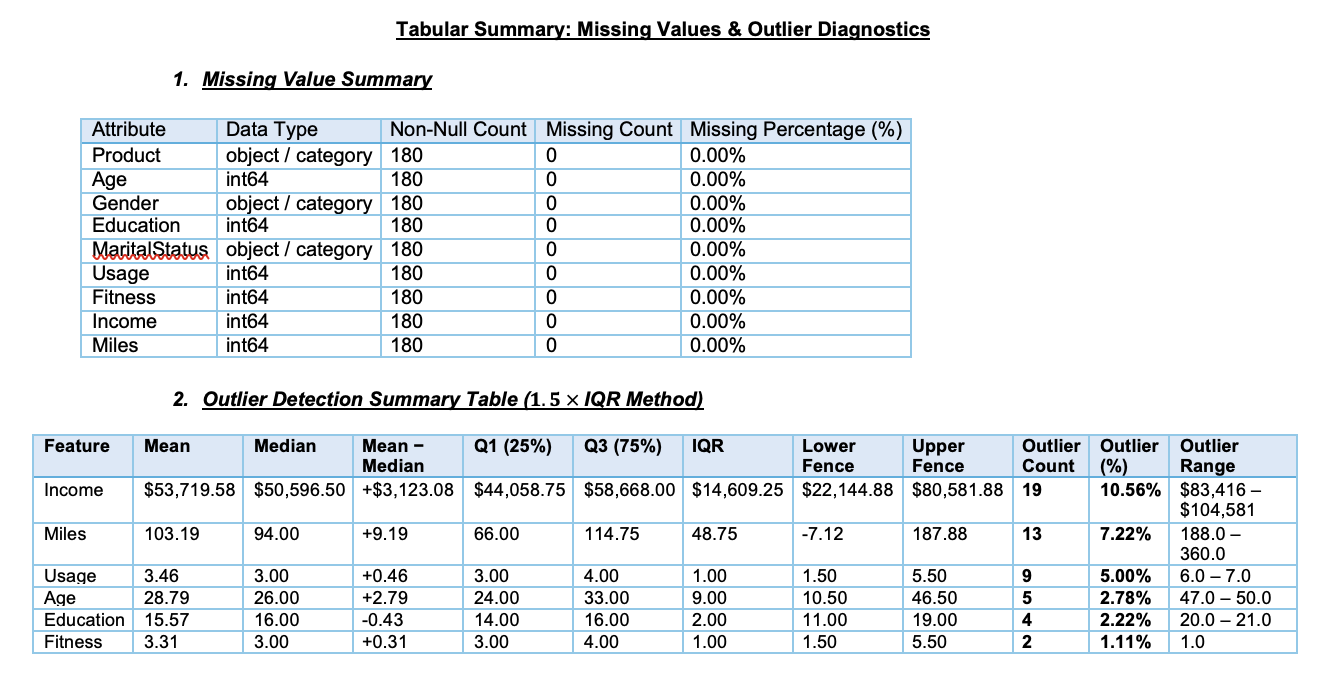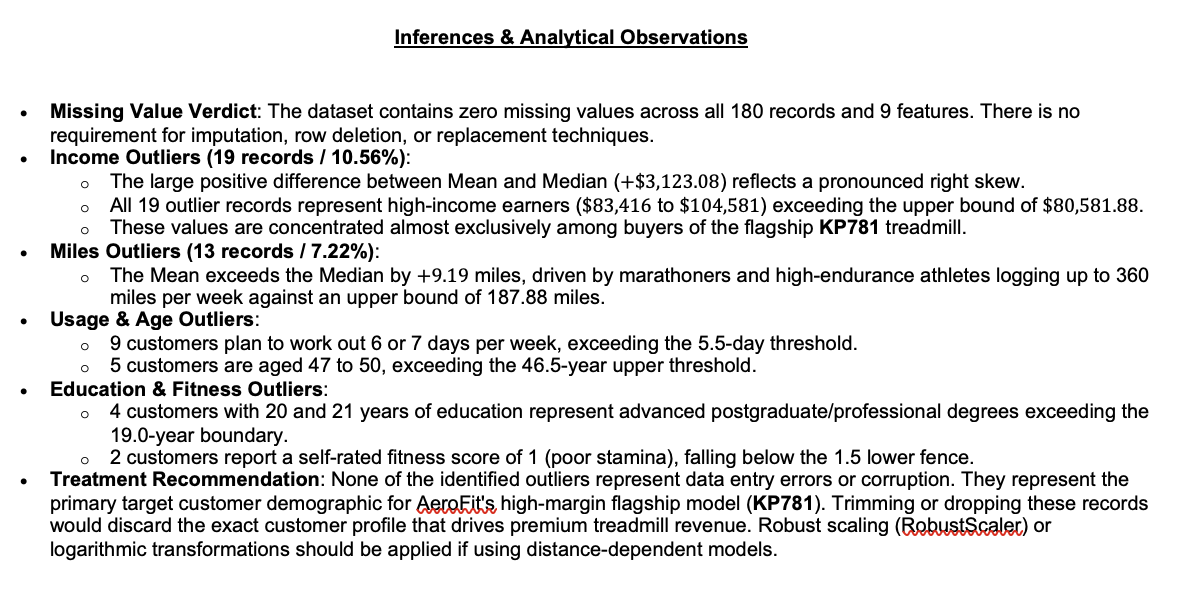

Question-5:⁠ ⁠Business Insights based on Non-Graphical and Visual Analysis (10 Points)

    A. Comments on the range of attributes



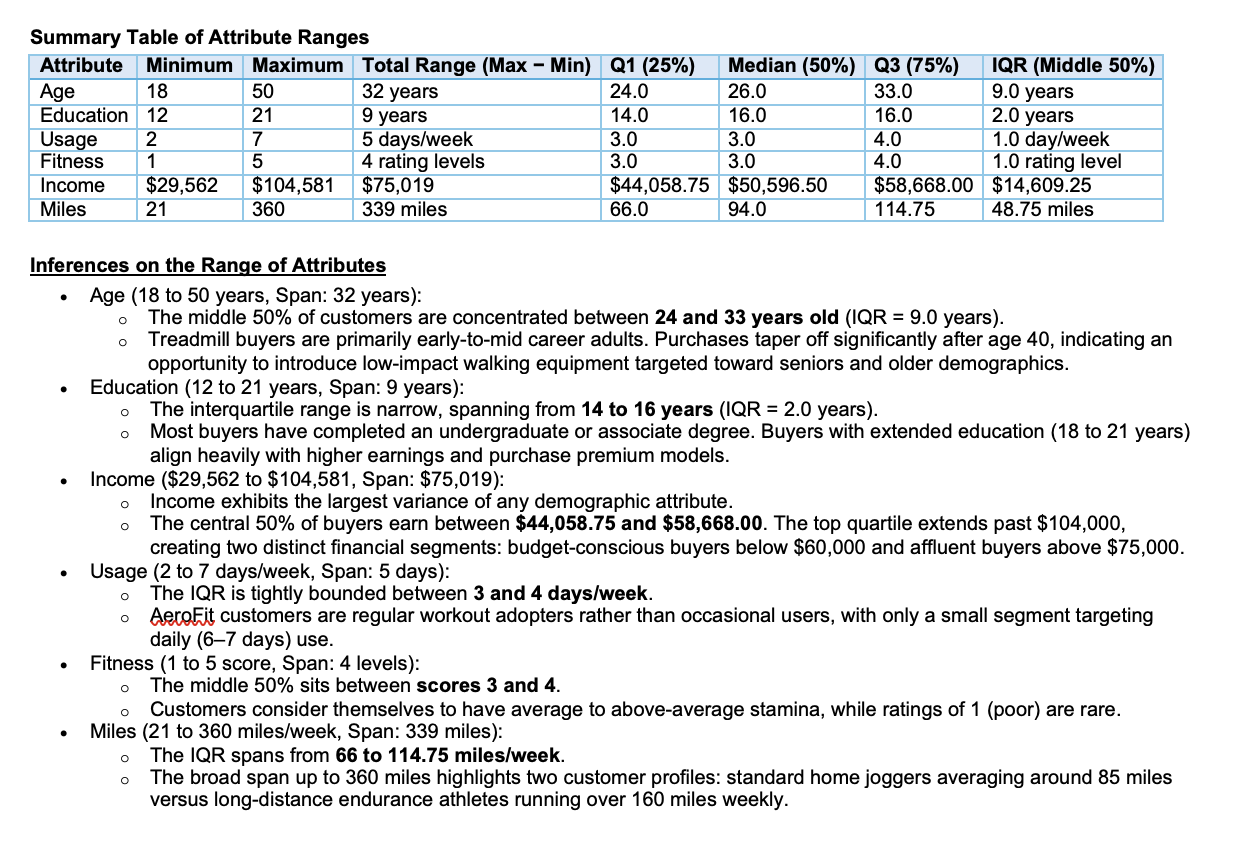

Question-5B. Comments on the distribution of the variables and relationship between them


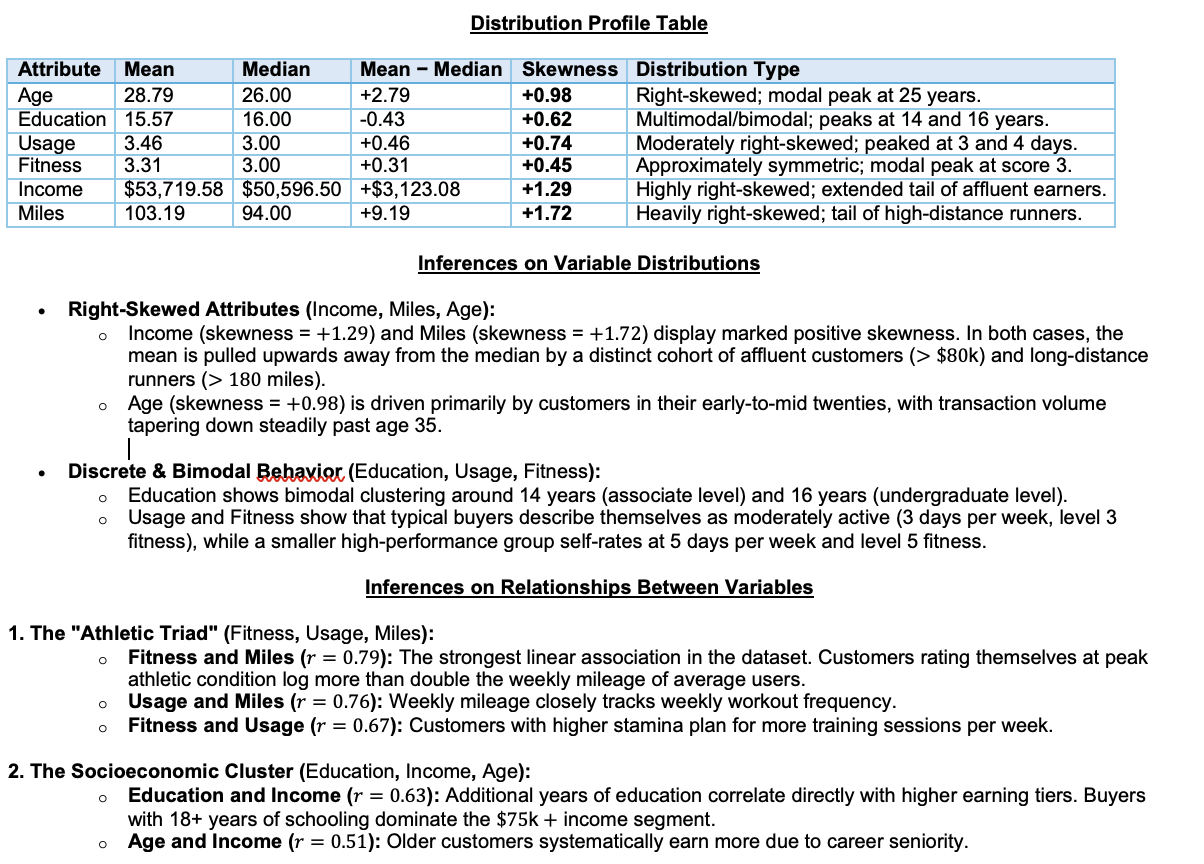 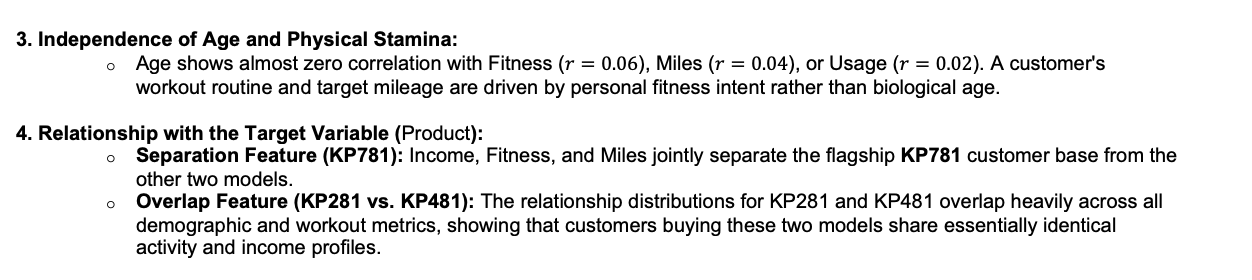

Question-5C. Comments for each univariate and bivariate plot

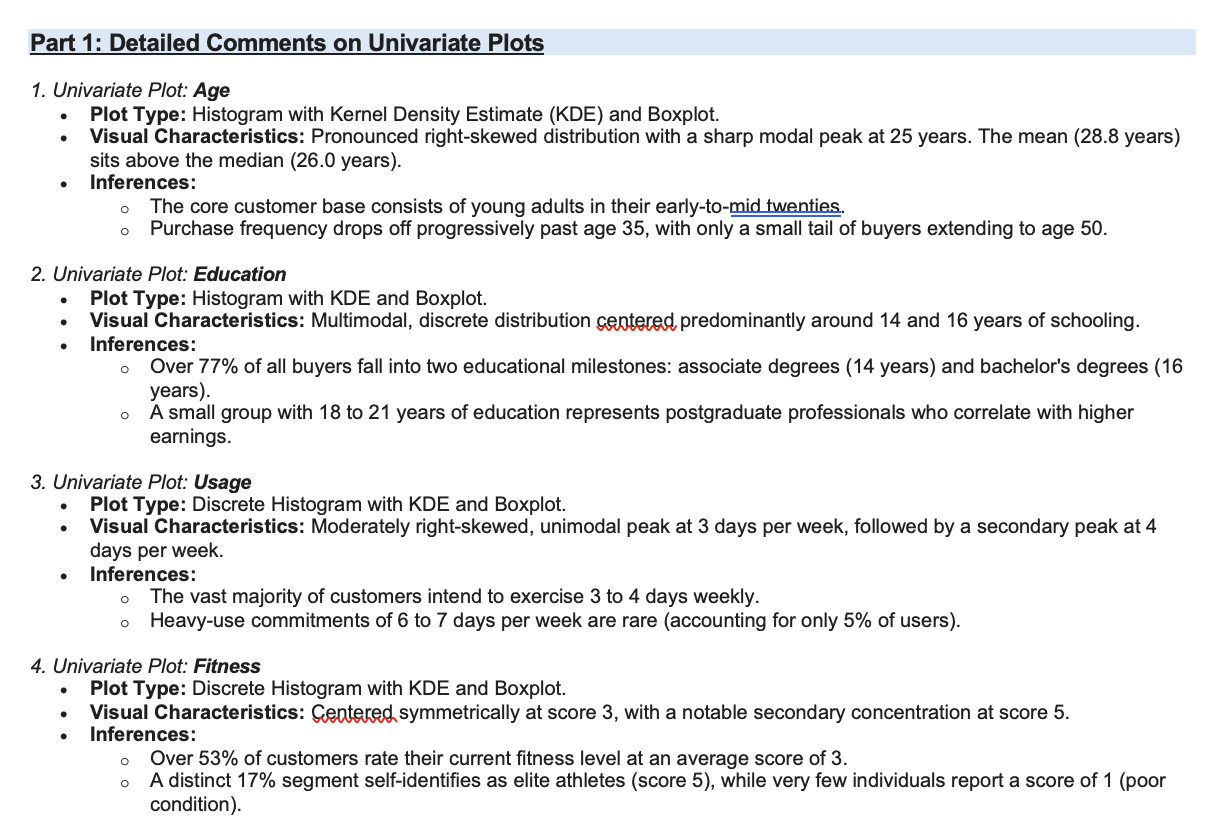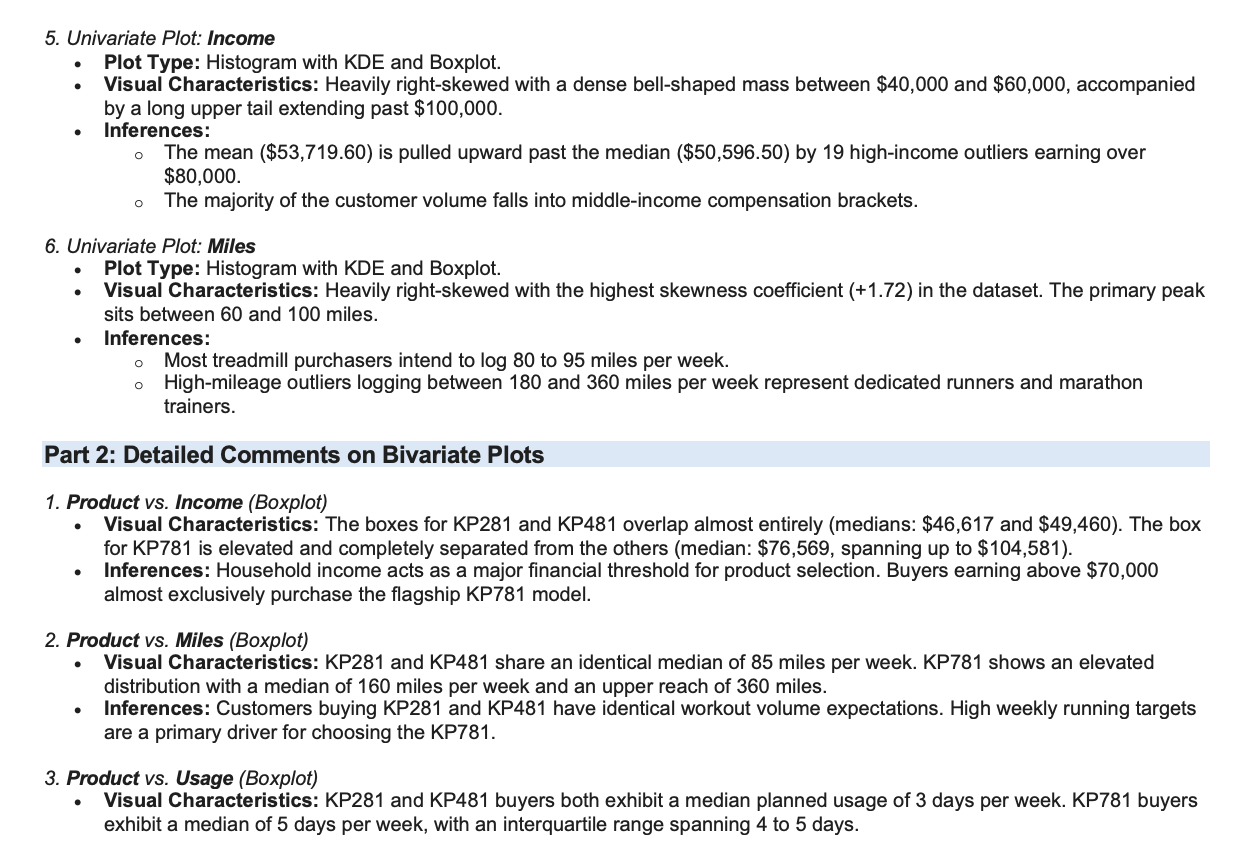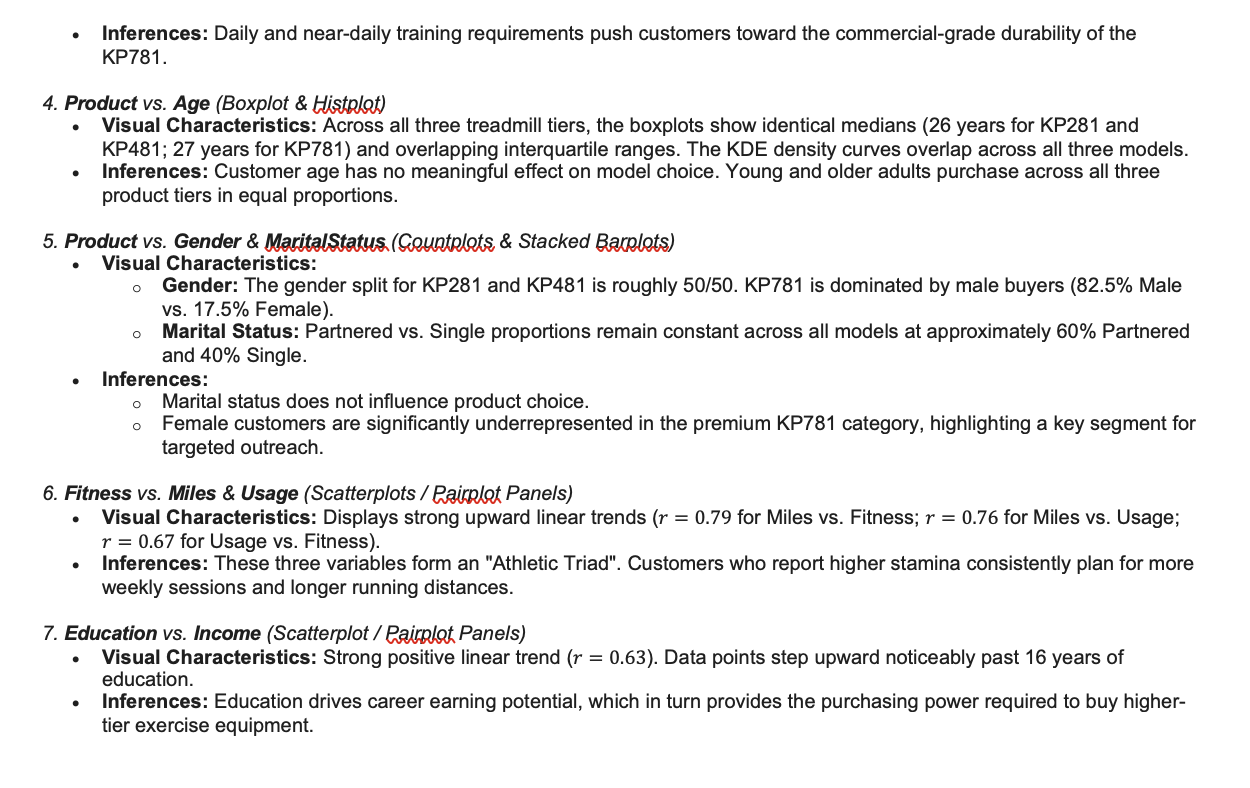

Question-6:⁠ ⁠Recommendations (10 Points) - Actionable items for business. No technical jargon. No complications. Simple action items that everyone can understand

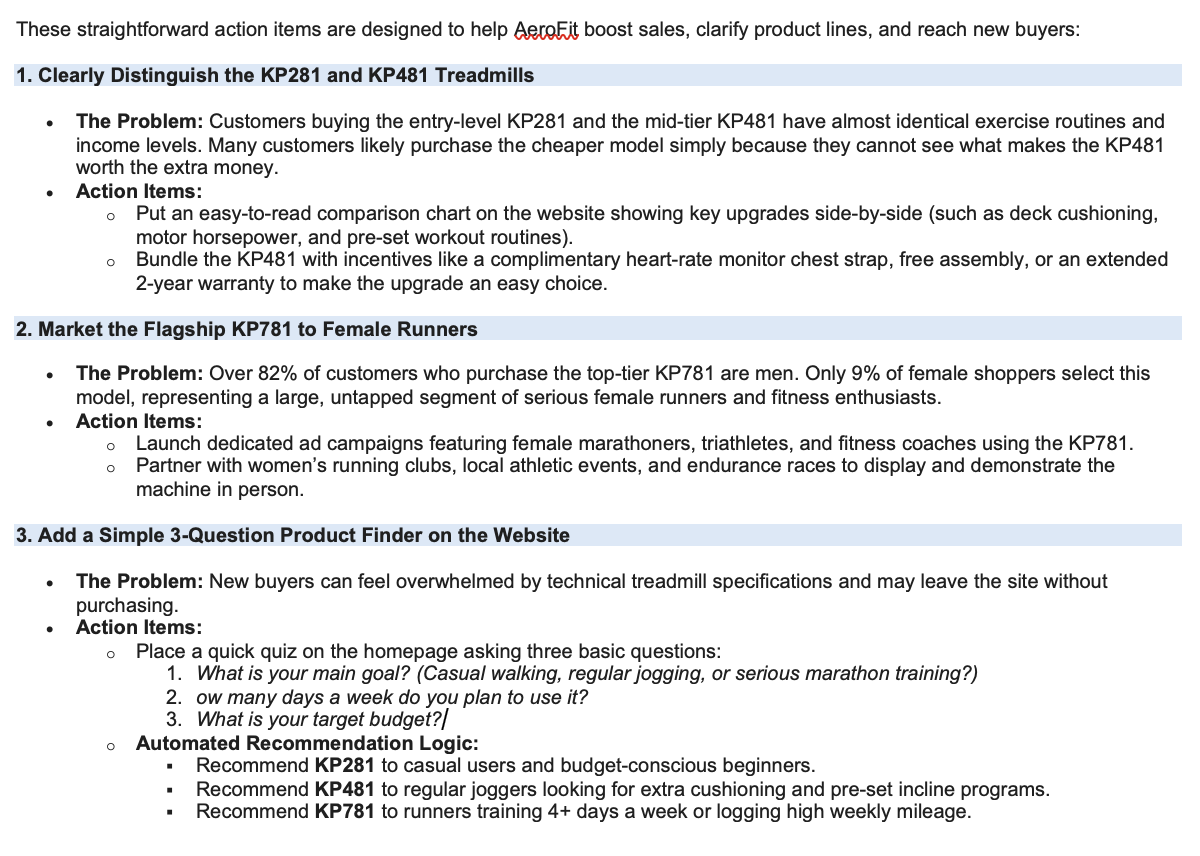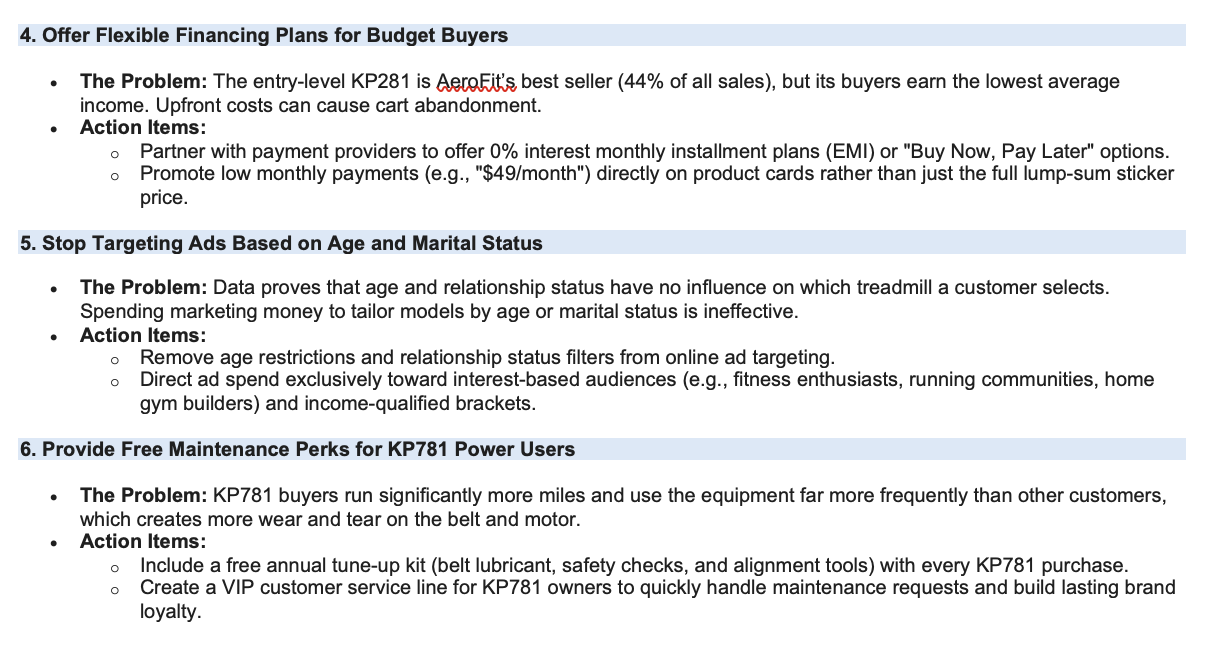